# Deliverable 2

# Deliverable 2 – Campus Coffee Shop Sales Pipeline

**Group members:** _Kristian Sheath, Philip Whitley_
**GitHub repository:** _[GitHub](https://github.com/SheathAndWhitley/INF201_deliverable_2)_

This notebook builds a small data pipeline for the Campus Coffee Shop Chain. It
1. finds all register log files in a nested folder structure and reads them regardless of encoding (UTF-8 / ISO-8859-1),
2. extracts valid sales lines with a regular expression and ignores system noise,
3. cleans price glitches with NumPy and corrects mis-scaled NOK prices,
4. analyses the data with pandas (hourly revenue, status pivot table, refund ratios),
5. saves the four required output files to `deliverables/`.

Tasks 1–4 define (and test) the functions, task 5 puts everything together. The discussion is at the end of the notebook.

In [45]:
# Libs for Deliverable 2
from pathlib import Path
import json
import re
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# All paths are built with pathlib, relative to the folder the notebook is run from
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "d2_data"
LOG_DIR = DATA_DIR / "2026"
CONFIG_PATH = DATA_DIR / "store_config.json"
OUTPUT_DIR = PROJECT_DIR / "deliverables"

STATUSES = ["SUCCESS", "REFUND", "CANCELLED"]



## Task 1

### Part 1 robust file reader

Every byte sequence is valid ISO-8859-1 (Latin-1 maps all 256 byte values to a character), so decoding with Latin-1 never fails, but it silently produces wrong characters for UTF-8 files (e.g. `Ã©` instead of `é`). UTF-8, on the other hand, is strict and raises `UnicodeDecodeError` on Latin-1 bytes such as `0xE9`. Therefore the reader **tries UTF-8 first** and only falls back to Latin-1 if that fails. The order matters.

In [46]:
def file_reader(file_path: str | Path) -> tuple[str, str]:
    '''
    Robust file reader that reads a text file using pathlib.
    Tries UTF-8 first and falls back to ISO-8859-1 (Latin-1), the encoding is not hard coded.
    Returns a tuple containing two strings: (file_text_content, encoding_used)
    '''
    path = Path(file_path)

    try:
        return path.read_text(encoding="utf-8"), "utf-8"
    except UnicodeDecodeError:
        return path.read_text(encoding="iso-8859-1"), "iso-8859-1"

### Part 2 regular expression

The pattern uses named groups for the 6 fields. It is anchored with `^` and `$` so the whole line must match, which means noise lines such as `--- PRINTER PAPER LOW ---`, `=== NETWORK SYNC OK ===` or `[DEBUG] BARCODE SCANNER REBOOTED` are rejected automatically, without having to list them. Item names may contain spaces and non-ASCII characters (lazy `.+?`), and the price accepts both `45` and `4.50`.

In [47]:
SALES_PATTERN = re.compile(
    r"^\[(?P<timestamp>\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\] "
    r"\[(?P<register_id>[^\]]+)\] "
    r"item=(?P<item>.+?) "
    r"price=(?P<price>\d+(?:\.\d+)?) "
    r"(?P<currency>[A-Z]{3}) "
    r"\((?P<status>SUCCESS|REFUND|CANCELLED)\)$"
)


def parse_sales_log(log_text: str) -> list[dict]:
    '''
    Parses raw log text and returns a list of dictionaries, one per valid sales line.
    Noise lines (printer, network, debug messages) do not match the pattern and are skipped.
    '''
    records = []
    for line in log_text.splitlines():
        match = SALES_PATTERN.match(line.strip())
        if match:
            record = match.groupdict()
            record["price"] = float(record["price"])
            records.append(record)

    return records

# T2 -   Recursive utility functions

### Part 1 Recursive directory search

In [48]:
def directory_searcher(directory_path: str | Path) -> list[Path]:
    '''
    Recursively finds all .log files in a nested directory and returns them as a list of Path objects.
    Constraint: does not use Path.glob, Path.rglob or os.walk, only Path.iterdir and recursion.
    '''
    path = Path(directory_path)

    if not path.is_dir():
        print(f"Path {path} is not a directory.")
        return []

    log_files = []
    for item in path.iterdir():
        if item.is_dir():
            log_files.extend(directory_searcher(item))
        elif item.is_file() and item.suffix == ".log":
            log_files.append(item)

    return log_files

In [49]:
for log_file in sorted(directory_searcher(LOG_DIR)):
    _, encoding = file_reader(log_file)
    print(f"{log_file.relative_to(DATA_DIR)}  ({encoding})")

2026/library_cafe/POS_01/register_sales.log  (utf-8)
2026/library_cafe/POS_02/register_sales.log  (utf-8)
2026/library_cafe/POS_03/register_sales.log  (utf-8)
2026/science_building/POS_01/register_sales.log  (utf-8)
2026/science_building/POS_02/register_sales.log  (utf-8)
2026/science_building/POS_03/register_sales.log  (utf-8)
2026/student_union/POS_01/register_sales.log  (utf-8)
2026/student_union/POS_02/register_sales.log  (utf-8)
2026/student_union/POS_03/register_sales.log  (utf-8)


### Part 2: Recursive search for active registers in `store_config.json`

The function does not assume anything about the structure of the file: a dictionary that has `"active": true` and an `"id"` is a register, and every value of a dictionary and every element of a list is searched recursively. This works for any depth and any combination of dicts and lists.

In [50]:
def get_active_registers(data) -> set[str]:
    '''
    Recursively traverses any combination of nested dicts and lists
    and returns a set of all register IDs where "active" is True.
    '''
    active_ids: set[str] = set()

    if isinstance(data, dict):
        # The dictionary itself is an active register
        if data.get("active") is True and "id" in data:
            active_ids.add(str(data["id"]))

        # Recurse into every value of the dictionary
        for value in data.values():
            active_ids |= get_active_registers(value)

    elif isinstance(data, list):
        # Recurse into every element of the list
        for item in data:
            active_ids |= get_active_registers(item)

    return active_ids


def load_active_registers_from_file(file_path: str | Path) -> set[str]:
    '''Loads store_config.json and returns the active register IDs using get_active_registers.'''
    config_data = json.loads(Path(file_path).read_text(encoding="utf-8"))
    return get_active_registers(config_data)

In [ ]:
# Test on a deeper, irregular structure than the real file
nested_test = {
    "registers": [{"id": "A", "active": True}, {"id": "B", "active": False}],
    "extra": [[{"stores": [{"registers": [{"id": "C", "active": True}]}]}], {"id": "D"}],
}
print("Test structure:", sorted(get_active_registers(nested_test)))   # expected ['A', 'C']
print("store_config.json:", sorted(load_active_registers_from_file(CONFIG_PATH)))

Test structure: ['A', 'C']
store_config.json: ['POS_01', 'POS_02', 'POS_03']


# T3 - Functions for cleaning and analysing datausing NumPy

### Part 1 Removing price outliers

A price $x$ is an outlier if $|x - \mu| > 3\sigma$. Outliers are replaced by the median of the **valid** (non-outlier) prices, so the glitches themselves do not influence the replacement value.

In [52]:
def price_fixer(data) -> np.ndarray:
    '''
    Converts input price data to a 1D NumPy float array.
    Detects hardware glitch outliers (|x - mean| > 3 * std),
    replaces them with the median of the valid prices and returns the cleaned array.
    '''
    prices = np.asarray(data, dtype=float).ravel()

    outlier_mask = np.abs(prices - prices.mean()) > 3 * prices.std()
    valid_prices = prices[~outlier_mask]

    cleaned_prices = prices.copy()
    if valid_prices.size > 0:
        cleaned_prices[outlier_mask] = np.median(valid_prices)

    return cleaned_prices

### Part 2 Refund ratio

$$\text{Refund Ratio} = \frac{\text{Refund Count}}{\text{Sales Count} + 10^{-6}}$$

The calculation is a single element-wise NumPy operation on whole arrays (no Python loop). The $\epsilon = 10^{-6}$ prevents division by zero.

In [53]:
def compute_refund_ratio(sales_count: np.ndarray, refund_count: np.ndarray) -> np.ndarray:
    '''
    Computes the element-wise refund ratio: refund_count / (sales_count + 1e-6)
    '''
    sales_arr = np.asarray(sales_count, dtype=float)
    refund_arr = np.asarray(refund_count, dtype=float)

    return refund_arr / (sales_arr + 1e-6)

# Task 4 – Data analysis with pandas

### Part 1: DataFrame from the transaction dictionaries

In [54]:
def create_dataframe_from_log_files(data: list[dict]) -> pd.DataFrame:
    '''
    Creates a pandas DataFrame from the transaction dictionaries,
    converts timestamp to datetime, sets it as the index and sorts chronologically.
    '''
    df = pd.DataFrame(data)
    df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y-%m-%d %H:%M:%S")
    return df.set_index("timestamp").sort_index()

### Part 2: Hourly revenue per item

In [55]:
def data_grouper(df: pd.DataFrame) -> pd.DataFrame:
    '''
    Groups the transactions by item, resamples them into 1-hour windows
    and calculates the total price (sum) per item per hour.
    '''
    return df.groupby("item").resample("1h")[["price"]].sum()

### Part 3: Pivot table of revenue per item and status

In [56]:
def create_pivot(df: pd.DataFrame) -> pd.DataFrame:
    '''
    Creates a pivot table displaying total transaction revenue
    grouped by item across the status categories (SUCCESS, REFUND, CANCELLED).
    '''
    pivot_table = df.pivot_table(index="item", columns="status", values="price", aggfunc="sum", fill_value=0)
    # Make sure all three status columns exist and are in a fixed order
    return pivot_table.reindex(columns=STATUSES, fill_value=0)

### Part 4: Refund ratio per item

**Definition of "sales count":** a log line with status `REFUND` or `CANCELLED` is not a completed sale, so we use the number of `SUCCESS` transactions as the sales count. Counting all transactions instead would make the denominator include the refunds themselves. All counts are computed in one `groupby`, and `compute_refund_ratio` is called **once** on whole arrays.

In [ ]:
def calculate_refund_ratio(df: pd.DataFrame) -> pd.DataFrame:
    '''
    Calculates the refund ratio per item using compute_refund_ratio from task 3.
    Sales count = number of SUCCESS transactions, refund count = number of REFUND transactions.
    '''
    # Count transactions per item and status (one row per item, one column per status)
    status_counts = pd.crosstab(df["item"], df["status"]).reindex(columns=STATUSES, fill_value=0)

    counts = pd.DataFrame({
        "sales_count": status_counts["SUCCESS"],
        "refund_count": status_counts["REFUND"],
    })
    counts["refund_ratio"] = compute_refund_ratio(counts["sales_count"].to_numpy(), counts["refund_count"].to_numpy())
    return counts

# T5 -  Create full workflow

### Part 1 Find all log files and extract the active register IDs

In [58]:
log_files = sorted(directory_searcher(LOG_DIR))
active_registers = load_active_registers_from_file(CONFIG_PATH)

print(f"Found {len(log_files)} log files")
print(f"Active registers: {sorted(active_registers)}")

Found 9 log files
Active registers: ['POS_01', 'POS_02', 'POS_03']


### Part 2 Read the logs and parse them into a list of dicts

In [59]:
all_records = []
noise_lines = 0
for log_file in log_files:
    content, encoding = file_reader(log_file)
    records = parse_sales_log(content)
    noise_lines += len(content.splitlines()) - len(records)
    all_records.extend(records)

active_records = [r for r in all_records if r["register_id"] in active_registers]

print(f"Valid transactions: {len(all_records)}, ignored noise lines: {noise_lines}")
print(f"Transactions from inactive registers removed: {len(all_records) - len(active_records)}")

Valid transactions: 720, ignored noise lines: 99
Transactions from inactive registers removed: 0


### Part 3 Build the initial DataFrame

In [60]:
df = create_dataframe_from_log_files(active_records)
df.head()

,register_id,item,price,currency,status
timestamp,,,,,
2026-10-15 07:00:31,POS_03,Espresso,3.08,EUR,SUCCESS
2026-10-15 07:00:31,POS_02,Espresso,3.35,EUR,SUCCESS
2026-10-15 07:00:54,POS_03,Cappuccino,4.00,NOK,SUCCESS
2026-10-15 07:01:47,POS_01,Croissant,4.07,NOK,SUCCESS
2026-10-15 07:01:50,POS_02,Espresso,2.91,NOK,SUCCESS


### Part 4 Remove price outliers

In [61]:
raw_prices = df["price"].to_numpy()
df["price"] = price_fixer(raw_prices)

replaced = raw_prices != df["price"].to_numpy()
print(f"Mean {raw_prices.mean():.2f}, std {raw_prices.std():.2f} -> outlier if price > {raw_prices.mean() + 3 * raw_prices.std():.2f}")
print(f"Replaced {replaced.sum()} outliers with raw values {np.unique(raw_prices[replaced])} by the median {df['price'][replaced].iloc[0]:.2f}")
print(f"Price range after cleaning: {df['price'].min():.2f} - {df['price'].max():.2f}")

Mean 27.90, std 151.02 -> outlier if price > 480.96
Replaced 17 outliers with raw values [999.] by the median 3.96
Price range after cleaning: 2.51 - 8.00


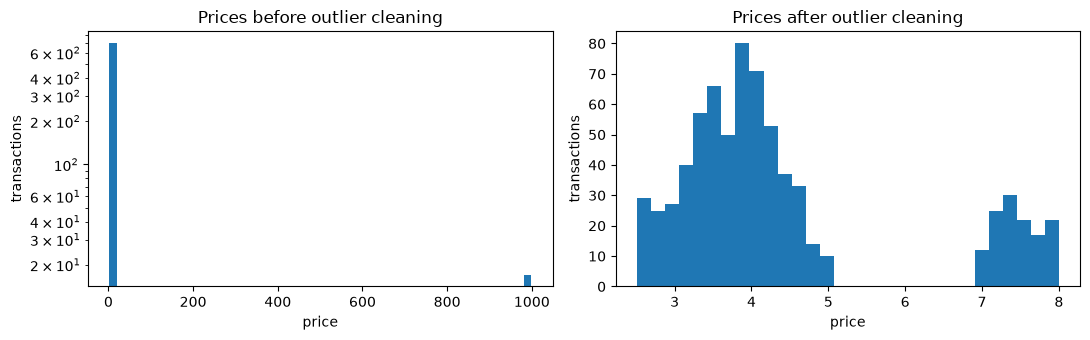

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(raw_prices, bins=60)
axes[0].set(title="Prices before outlier cleaning", xlabel="price", ylabel="transactions", yscale="log")
axes[1].hist(df["price"], bins=30)
axes[1].set(title="Prices after outlier cleaning", xlabel="price", ylabel="transactions")
plt.tight_layout()
plt.show()

### Part 5 Currency correction, ( NOK x 10 )

In [63]:
df.loc[df["currency"] == "NOK", "price"] *= 10.0

df.groupby("currency")["price"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
currency,,,,,,,,
EUR,253.0,4.30,1.50,2.51,3.34,3.88,4.5,7.97
NOK,224.0,43.64,14.72,25.40,34.68,39.60,44.2,79.90
USD,243.0,4.56,1.60,2.51,3.49,4.03,4.7,8.00


### Part 6 Hourly revenue, pivot table and refund ratios

In [64]:
hourly_revenue = data_grouper(df)
hourly_table = hourly_revenue["price"].unstack("item").round(2)
hourly_table

item,Cappuccino,Croissant,Espresso,Latte,Muffin,Sandwich
timestamp,,,,,,
2026-10-15 07:00:00,682.56,1133.58,674.91,598.48,782.87,1138.05
2026-10-15 08:00:00,1047.29,906.64,686.36,805.64,687.66,2114.21
2026-10-15 09:00:00,138.79,118.04,131.47,60.28,125.75,138.31


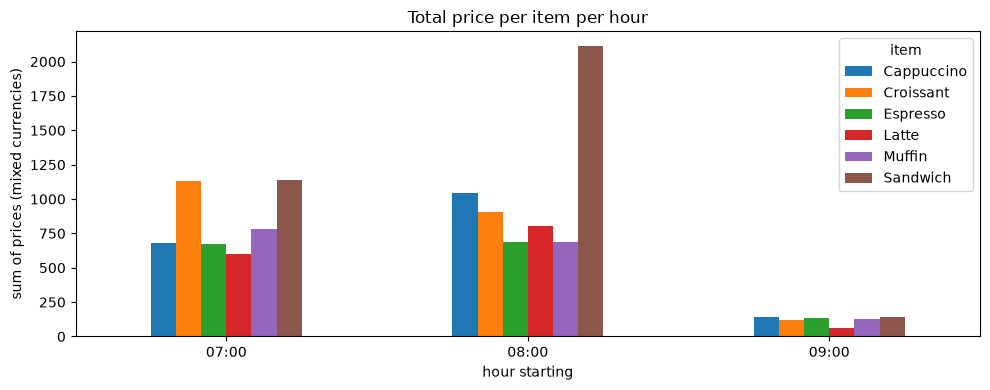

In [65]:
ax = hourly_table.set_axis(hourly_table.index.strftime("%H:%M")).plot(kind="bar", figsize=(10, 4), rot=0)
ax.set(title="Total price per item per hour", xlabel="hour starting", ylabel="sum of prices (mixed currencies)")
plt.tight_layout()
plt.show()

In [66]:
pivot_table = create_pivot(df).round(2)
pivot_table

status,SUCCESS,REFUND,CANCELLED
item,,,
Cappuccino,1355.19,254.67,258.78
Croissant,1492.78,354.48,311.00
Espresso,1150.25,191.33,151.16
Latte,1043.93,227.55,192.92
Muffin,1092.32,268.79,235.17
Sandwich,2480.33,625.09,285.15


In [67]:
refund_ratios = calculate_refund_ratio(df)
refund_ratios.round(4)

,sales_count,refund_count,refund_ratio
item,,,
Cappuccino,79,19,0.2405
Croissant,88,19,0.2159
Espresso,93,21,0.2258
Latte,66,14,0.2121
Muffin,79,22,0.2785
Sandwich,89,20,0.2247


In [ ]:
# The crosstab behind the refund ratio: number of transactions per item and status
status_counts = pd.crosstab(df["item"], df["status"]).reindex(columns=STATUSES, fill_value=0)
display(status_counts)

ax = status_counts.plot(kind="bar", figsize=(10, 4), rot=0)
ax.set(title="Transactions per item and status", xlabel="item", ylabel="number of transactions")
for container in ax.containers:
    ax.bar_label(container, padding=2)
plt.tight_layout()
plt.show()

### Part 7 Save into output files

In [68]:
OUTPUT_DIR.mkdir(exist_ok=True)

# cleaned_transactions.csv
df.round({"price": 2}).reset_index().to_csv(OUTPUT_DIR / "cleaned_transactions.csv", index=False)

# hourly_revenue.json: {item: {hour: total}}
hourly_json = {
    item: {ts.strftime("%Y-%m-%d %H:%M"): round(float(total), 2) for ts, total in group.droplevel("item").items()}
    for item, group in hourly_revenue["price"].groupby(level="item")
}
(OUTPUT_DIR / "hourly_revenue.json").write_text(json.dumps(hourly_json, indent=2), encoding="utf-8")

# status_pivot_table.csv
pivot_table.to_csv(OUTPUT_DIR / "status_pivot_table.csv")

# item_refund_ratios.csv
refund_ratios.round({"refund_ratio": 4}).to_csv(OUTPUT_DIR / "item_refund_ratios.csv")

for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"{f.name:<28} {f.stat().st_size:>6} bytes")

cleaned_transactions.csv      38082 bytes
hourly_revenue.json             699 bytes
item_refund_ratios.csv          173 bytes
status_pivot_table.csv          213 bytes


# Discussion

### Summary Of the Results

* 9 log files were found in the nested directory, containing 720 valid transaction and 99 noise lines.

* Valid registers are POS_01, POS_02 and POS_03, POS_04 was registered and inactive.

* A total of 17 prices outliers were found in the datasets


# Summary of AI Usage

* Used GitHub Copilot in VScode, made a strict rules markdown file for it to only read the code and give feedback, never write or edit a file.
 * Was used during coding to verify our code and check for better solutions.